# Week 7 · Estimation & Confidence Intervals + Hypothesis Testing Framework

*DS 207 · Week 7*

Every business decision built on a sample rests on one question: how far can the sample be trusted? This notebook turns that question into three working tools: an estimate with a standard error, a confidence interval that reports the estimate's precision honestly, and a hypothesis test that turns evidence into a documented decision. It closes by showing that the interval and the test are the same mathematics read two ways.

*EC Corro, built in collaboration with Claude, ChatGPT, and Gemini*

## Learning Objectives

By the end of this notebook you will be able to:

- Explain what makes a point estimate good (unbiased, precise, consistent) and compute the standard error of a sample mean as $s/\sqrt{n}$.
- Construct a confidence interval for a mean, state precisely what its confidence level does and does not promise, and name the levers that control its width.
- Carry out a hypothesis test for a mean: state $H_0$ and $H_1$, compute the test statistic and p-value, apply a decision rule, and choose between a z-test and a t-test.
- Describe Type I and Type II errors in business terms, and use their costs to choose a significance level and a sample size.
- Show why a confidence interval and a two-sided hypothesis test always agree, and use the pair together to reach a decision.

**Prerequisites:** Week 1 descriptive statistics (mean, standard deviation), Week 2 distribution shape (skewness), Week 5 conditional probability, and Week 6 sampling distributions and the Central Limit Theorem.

## Business Context

Isla Contact Solutions is a Cebu-based business process outsourcing (BPO) firm that runs inbound customer support for a national telecom client. Paolo Reyes, Operations Director, is weighing a three-year, site-wide licence for an agent-assist tool that suggests answers while an agent is on a call. The licence costs ₱5.0 million per year plus ₱3.0 million for rollout, ₱18.0 million over the contract. The site handles 3.0 million calls a year at a loaded agent cost of ₱4.00 per minute, so every minute of average handle time (AHT) removed is worth ₱36.0 million over three years, and the tool breaks even at a reduction of 0.5 minute per call. Before the pilot, the Tech Support queue averaged 11.0 minutes per call with a historical standard deviation of 4.0 minutes. A 24-agent team piloted the tool for four weeks, and Quality Assurance audited a random sample of 400 of their calls. The stakeholder question this week answers: *Did the pilot really lower handle time, how precisely do we know by how much, and is the evidence strong enough to commit ₱18.0 million?*

Because Paolo only ever sees the 400-call audit sample, this notebook also simulates the pilot team's full-year call population (100,000 calls). That lets each method be checked against a true value that, in practice, stays unknown.

In [25]:
# Setup: libraries, seed, business constants, and the pilot data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.weightstats import DescrStatsW, ztest

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

rng = np.random.default_rng(207)

# Pre-pilot benchmark for the Tech Support queue (minutes per call)
MU0, SIGMA0 = 11.0, 4.0

# Contract economics (PHP)
CALLS_PER_YEAR, COST_PER_MIN = 3_000_000, 4.00
LICENCE_PER_YEAR, ROLLOUT, YEARS = 5_000_000, 3_000_000, 3
total_cost = LICENCE_PER_YEAR * YEARS + ROLLOUT                  # 18.0 million
value_per_minute = CALLS_PER_YEAR * COST_PER_MIN * YEARS           # 36.0 million per minute removed, over the contract
breakeven = total_cost / value_per_minute                          # 0.5 minute per call

# Simulated population: every call the pilot team would handle in a year (right-skewed, gamma-shaped)
pop_mean, pop_sd = 10.3, 4.0
population = np.round(rng.gamma((pop_mean / pop_sd) ** 2, pop_sd ** 2 / pop_mean, 100_000), 1)
mu_true, sigma_true = population.mean(), population.std()

# The 400-call random audit sample that Paolo actually sees
pilot = pd.DataFrame({"call_id": np.arange(1, 401),
                      "aht_min": population[rng.choice(population.size, 400, replace=False)]})

print(f"Break-even reduction: {breakeven:.2f} minute per call (AHT at or below {MU0 - breakeven:.1f} minutes)")
print(f"Contract cost: ₱{total_cost / 1e6:.1f} million; value of one minute removed: ₱{value_per_minute / 1e6:.1f} million")
print("\nAudit sample, handle time in minutes:")
print(pilot["aht_min"].describe().round(2).to_string())

Break-even reduction: 0.50 minute per call (AHT at or below 10.5 minutes)
Contract cost: ₱18.0 million; value of one minute removed: ₱36.0 million

Audit sample, handle time in minutes:
count    400.00
mean      10.19
std        3.99
min        2.80
25%        7.30
50%        9.80
75%       12.42
max       26.70


### Subtopic 1 · Point Estimation and the Standard Error

**Business Hook:** Paolo's first question is *"The audited pilot calls average a certain number of minutes. How much should I trust that single number as the pilot team's true AHT?"*

## Intuition & Analogy

Think of tasting one spoonful from a large pot of sinigang. The spoonful is a **sample**, the flavour of the whole pot is the **parameter** you care about, and your verdict on the pot is the **point estimate**. Three things make that verdict trustworthy:

- **Unbiased.** The pot was stirred. If you tasted many spoonfuls, the verdicts would centre on the true flavour instead of leaning salty or bland. For a call audit, "stirred" means the calls were chosen at random, not cherry-picked.
- **Precise.** Spoonfuls from the same pot give similar verdicts. A bigger spoonful (more calls) tightens them; a pot with wildly uneven flavour (highly variable calls) loosens them.
- **Consistent.** The more you taste, the closer the verdict gets to the truth.

Precision has a number. The typical gap between one spoonful's verdict and the pot's true flavour is the **standard error (SE)**, and for a sample mean it is the one formula that governs everything else in this notebook:

$$SE(\bar{x}) = \frac{s}{\sqrt{n}}$$

SE grows with the spread of individual calls ($s$) and shrinks with the square root of the number of calls ($n$). Every confidence interval and every test that follows is built from it.

## Theory — By Hand

**Vocabulary.** The parameter $\mu$ is the pilot team's true mean AHT. The estimator $\bar{X}$ is the rule "add the calls, divide by $n$"; the estimate $\bar{x}$ is the number that rule produces from one particular sample. The sample standard deviation uses the $n-1$ divisor, which keeps $s^2$ unbiased for $\sigma^2$:

$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i, \qquad s = \sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}, \qquad SE = \frac{s}{\sqrt{n}}$$

**Worked example: four consecutive audited calls (rows 8 to 11 of the data frame).** Handle times in minutes: 8.8, 5.5, 8.5, 11.1.

1. Mean: $\bar{x} = \dfrac{8.8 + 5.5 + 8.5 + 11.1}{4} = \dfrac{33.9}{4} = 8.475$
2. Deviations from the mean: $+0.325$, $-2.975$, $+0.025$, $+2.625$
3. Squared deviations: 0.105625, 8.850625, 0.000625, 6.890625, which sum to 15.8475
4. Variance and SD: $s^2 = \dfrac{15.8475}{4-1} = 5.2825$, so $s = 2.2984$
5. Standard error: $SE = \dfrac{2.2984}{\sqrt{4}} = 1.1492$

Four calls put the estimate at 8.475 minutes, typically off by about 1.15 minutes. That is far too coarse for a ₱18.0 million decision.

**How SE responds to $n$.** Holding $s \approx 4.0$ minutes (the benchmark SD):

| Calls audited, $n$ | 4 | 25 | 100 | 400 | 1,600 |
|---|---|---|---|---|---|
| $SE = 4.0/\sqrt{n}$ | 2.00 | 0.80 | 0.40 | 0.20 | 0.10 |

Each fourfold increase in audited calls halves the standard error, so precision is bought at a diminishing rate.

## By Tool

The code first reproduces the four-call result, then scales to the full audit sample, then asks two questions about estimators themselves: which one is better, and does the SE formula really describe how audits behave?

In [2]:
# 1. Reproduce the by-hand result on the four-call extract (rows 8 to 11)
extract = pilot["aht_min"].iloc[8:12].to_numpy()
x_bar = extract.mean()
s = extract.std(ddof=1)                 # ddof=1 gives the n-1 divisor
se = s / np.sqrt(extract.size)
print(f"Extract: {extract}")
print(f"mean = {x_bar:.3f}, s = {s:.4f}, SE = {se:.4f}")

Extract: [ 8.8  5.5  8.5 11.1]
mean = 8.475, s = 2.2984, SE = 1.1492


n = 400, mean = 10.194, s = 3.987, SE = 0.1994
True pilot-team mean (known only because it was simulated): 10.304
Estimation error: -0.109 minute = -0.55 standard errors


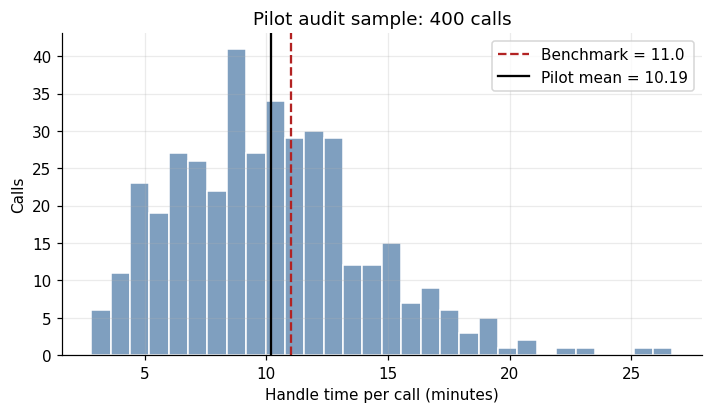

In [3]:
# 2. Full-scale estimate from the 400-call audit, checked against the (normally unknowable) truth
n = len(pilot)
x_bar_full = pilot["aht_min"].mean()
s_full = pilot["aht_min"].std(ddof=1)
se_full = s_full / np.sqrt(n)
print(f"n = {n}, mean = {x_bar_full:.3f}, s = {s_full:.3f}, SE = {se_full:.4f}")
print(f"True pilot-team mean (known only because it was simulated): {mu_true:.3f}")
print(f"Estimation error: {x_bar_full - mu_true:+.3f} minute = {(x_bar_full - mu_true) / se_full:+.2f} standard errors")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(pilot["aht_min"], bins=30, color="#7f9fbf", edgecolor="white")
ax.axvline(MU0, color="firebrick", ls="--", label=f"Benchmark = {MU0:.1f}")
ax.axvline(x_bar_full, color="black", label=f"Pilot mean = {x_bar_full:.2f}")
ax.set_xlabel("Handle time per call (minutes)"); ax.set_ylabel("Calls")
ax.set_title("Pilot audit sample: 400 calls"); ax.legend(); plt.show()

True mean of the pilot-team population: 10.304
               average of estimates  bias vs true mean  SD of estimates (SE)
sample mean                  10.312              0.008                 0.409
sample median                 9.798             -0.505                 0.496


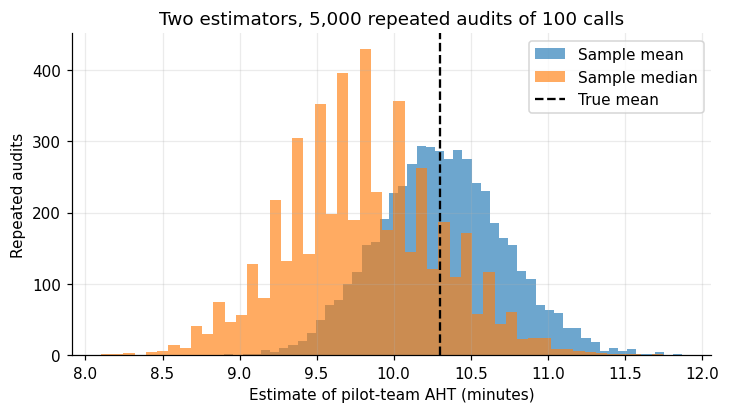

In [4]:
# 3. What makes an estimate good? Two estimators of the mean across 5,000 repeated audits of 100 calls
reps, n_audit = 5000, 100
audits = population[rng.integers(0, population.size, size=(reps, n_audit))]
means = audits.mean(axis=1)
medians = np.median(audits, axis=1)

comparison = pd.DataFrame(
    {"average of estimates": [means.mean(), medians.mean()],
     "bias vs true mean": [means.mean() - mu_true, medians.mean() - mu_true],
     "SD of estimates (SE)": [means.std(ddof=1), medians.std(ddof=1)]},
    index=["sample mean", "sample median"]).round(3)
print(f"True mean of the pilot-team population: {mu_true:.3f}")
print(comparison.to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(means, bins=50, alpha=0.65, label="Sample mean")
ax.hist(medians, bins=50, alpha=0.65, label="Sample median")
ax.axvline(mu_true, color="black", ls="--", label="True mean")
ax.set_xlabel("Estimate of pilot-team AHT (minutes)"); ax.set_ylabel("Repeated audits")
ax.set_title("Two estimators, 5,000 repeated audits of 100 calls"); ax.legend(); plt.show()

   n  simulated SE  formula: sigma/sqrt(n)
  25         0.818                     0.8
 100         0.388                     0.4
 400         0.202                     0.2
1600         0.100                     0.1


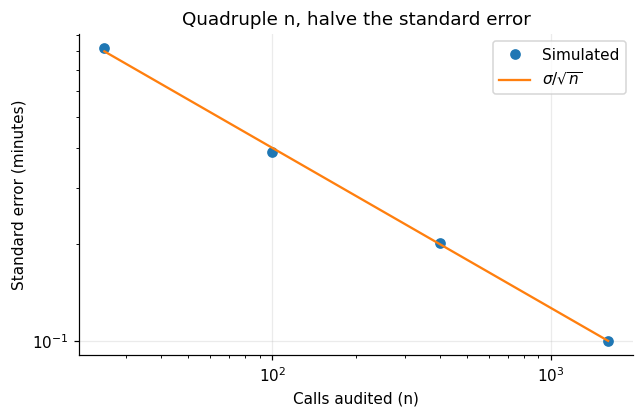

In [5]:
# 4. Standard error shrinks with the square root of n
rows = []
for n_i in [25, 100, 400, 1600]:
    sim_means = population[rng.integers(0, population.size, size=(4000, n_i))].mean(axis=1)
    rows.append({"n": n_i,
                 "simulated SE": sim_means.std(ddof=1),
                 "formula: sigma/sqrt(n)": sigma_true / np.sqrt(n_i)})
se_table = pd.DataFrame(rows).round(3)
print(se_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(se_table["n"], se_table["simulated SE"], "o", label="Simulated")
ax.plot(se_table["n"], se_table["formula: sigma/sqrt(n)"], "-", label=r"$\sigma/\sqrt{n}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Calls audited (n)"); ax.set_ylabel("Standard error (minutes)")
ax.set_title("Quadruple n, halve the standard error"); ax.legend(); plt.show()

**Reading the result.**

- The four-call extract reproduces the hand calculation exactly: mean 8.475, SE 1.1492.
- At full scale the audit gives a mean of 10.19 minutes with SE 0.20. The true pilot-team mean is 10.30, so this estimate missed by 0.11 minute, about 0.5 standard errors, which is an ordinary miss.
- Across repeated audits the sample mean centres on the truth (average estimate 10.31), while the sample median does not (9.80). The median estimates the middle call, not the average call, and call durations are right-skewed. The mean is also the more precise of the two (SE 0.409 versus 0.496).
- The simulated standard errors track $\sigma/\sqrt{n}$ at every sample size, so the formula describes how audits actually behave.

## Business Application

**Stakeholder: Paolo Reyes, Operations Director.**

- **Working estimate.** The pilot team averaged 10.19 minutes per call, 0.81 minutes below the 11.0-minute benchmark, with a standard error of 0.20 minute.
- **How to quote it.** Paolo can report the estimate together with its precision instead of as a bare number. A reduction of 0.81 minutes is already above the 0.5-minute break-even, but a standard error of 0.20 minute says the true figure could sit a few tenths of a minute either side.
- **Price of precision.** Because SE falls with $\sqrt{n}$, halving the uncertainty takes four times the audited calls. Paolo can ask QA to cost that extension against the ₱18.0 million at stake before deciding whether more precision is worth buying.

### Subtopic 2 · Confidence Intervals: Construction and Correct Interpretation

**Business Hook:** Paolo's next question is *"Give me a range for the pilot team's true AHT that I can put in front of the finance committee, and tell me exactly what that range promises."*

## Intuition & Analogy

A point estimate is one spear thrown at a fish you cannot see. A confidence interval is a net woven around that throw. Imagine Isla repeating the 400-call audit again and again, each time computing the estimate and weaving a net of width set by the standard error. Most nets would catch the fish, a few would miss. The **confidence level** is the catch rate of the *method* over many audits.

Two readings sound natural and are wrong:

- **Wrong:** "There is a 95% probability that the true mean lies in this interval." The true mean is one fixed number. Once the interval is computed it either contains it or it does not. The 95% describes the netting method, not this particular net.
- **Wrong:** "95% of individual calls fall inside the interval." The interval is about the *average* call. Individual calls scatter far more widely than their average does.

**Correct:** "Intervals built this way capture the true mean in 95% of repeated audits, and this is one of them."

Three levers set the width: the confidence level (more confidence means a wider net), the variability $s$ (noisier calls mean a wider net), and the sample size $n$ (more calls mean a narrower net).

## Theory — By Hand

For a mean with unknown $\sigma$, the interval is

$$\bar{x} \pm t^{*}_{n-1}\cdot SE, \qquad SE = \frac{s}{\sqrt{n}}$$

where $t^{*}_{n-1}$ is the point that leaves 2.5% in each tail of the t-distribution with $n-1$ degrees of freedom (for a 95% interval). The t multiplier is larger than the normal 1.96 because $s$ is itself an estimate; the penalty fades as $n$ grows.

**Worked example: the same four calls** ($\bar{x}=8.475$, $SE=1.1492$, $df=3$):

1. Multiplier for 95% confidence with 3 degrees of freedom: $t^{*}_{3} = 3.182$
2. Margin of error: $3.182 \times 1.1492 = 3.657$
3. Interval: $8.475 \pm 3.657 = (4.82,\ 12.13)$

If $\sigma = 4.0$ were known instead, the multiplier would be 1.96 and $SE = 4.0/\sqrt{4} = 2.0$, giving $8.475 \pm 3.920 = (4.55,\ 12.39)$.

The four-call interval runs from under 5 to over 12 minutes. It contains both the 11.0-minute benchmark and the 10.5-minute break-even, so four calls cannot support any conclusion. Width is information: a wide interval is the honest statement that the sample is too thin.

## By Tool

The code reproduces the hand interval, builds the full-scale interval three independent ways, shows how the confidence level changes the width, and then tests the meaning of "95%" by repeating the audit 10,000 times.

In [6]:
# 1. Reproduce the by-hand interval for the four-call extract
t_star_3 = stats.t.ppf(0.975, df=3)
moe_3 = t_star_3 * se
print(f"t* (df = 3) = {t_star_3:.3f}")
print(f"Margin of error = {moe_3:.3f}")
print(f"95% CI from the formula: ({x_bar - moe_3:.3f}, {x_bar + moe_3:.3f})")
print("95% CI from scipy:      ", tuple(round(v, 3) for v in stats.t.interval(0.95, df=3, loc=x_bar, scale=se)))

t* (df = 3) = 3.182
Margin of error = 3.657
95% CI from the formula: (4.818, 12.132)
95% CI from scipy:       (np.float64(4.818), np.float64(12.132))


In [7]:
# 2. Full-scale 95% interval three ways, and how the confidence level changes the width
alpha = 0.05
t_star = stats.t.ppf(1 - alpha / 2, df=n - 1)
moe = t_star * se_full
ci_manual = (x_bar_full - moe, x_bar_full + moe)
ci_scipy = stats.t.interval(0.95, df=n - 1, loc=x_bar_full, scale=se_full)
ci_sm = DescrStatsW(pilot["aht_min"]).tconfint_mean(alpha=0.05)
ci_lo, ci_hi = ci_manual
print(f"t* (df = {n - 1}) = {t_star:.3f}, margin of error = {moe:.3f}")
print(f"Manual:      ({ci_manual[0]:.3f}, {ci_manual[1]:.3f})")
print(f"scipy:       ({ci_scipy[0]:.3f}, {ci_scipy[1]:.3f})")
print(f"statsmodels: ({ci_sm[0]:.3f}, {ci_sm[1]:.3f})")

levels = pd.DataFrame([
    {"confidence level": f"{lvl:.0%}",
     "t*": stats.t.ppf(1 - (1 - lvl) / 2, df=n - 1),
     "lower": x_bar_full - stats.t.ppf(1 - (1 - lvl) / 2, df=n - 1) * se_full,
     "upper": x_bar_full + stats.t.ppf(1 - (1 - lvl) / 2, df=n - 1) * se_full}
    for lvl in (0.90, 0.95, 0.99)])
levels["width"] = levels["upper"] - levels["lower"]
print("\n" + levels.round(3).to_string(index=False))

inside = pilot["aht_min"].between(ci_lo, ci_hi).mean()
print(f"\nShare of individual calls that fall inside the 95% interval: {inside:.1%}")

t* (df = 399) = 1.966, margin of error = 0.392
Manual:      (9.803, 10.586)
scipy:       (9.803, 10.586)
statsmodels: (9.803, 10.586)

confidence level    t*  lower  upper  width
             90% 1.649  9.866 10.523  0.657
             95% 1.966  9.803 10.586  0.784
             99% 2.588  9.679 10.710  1.032

Share of individual calls that fall inside the 95% interval: 6.5%


Intervals that captured the true mean (10.304): 95.1% of 10,000


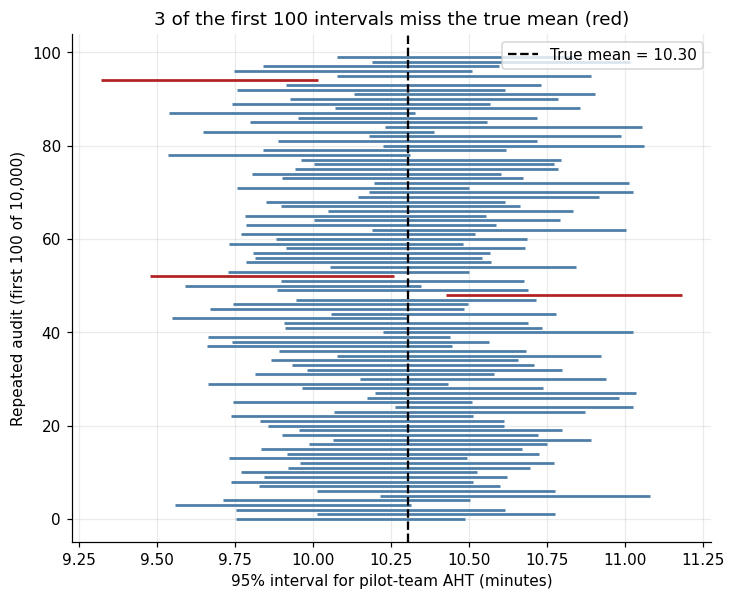

In [8]:
# 3. What does "95%" mean? Repeat the 400-call audit 10,000 times and count how often the interval captures the true mean
reps, n_audit = 10_000, 400
audits = population[rng.integers(0, population.size, size=(reps, n_audit))]
rep_mean = audits.mean(axis=1)
rep_half = stats.t.ppf(0.975, df=n_audit - 1) * audits.std(axis=1, ddof=1) / np.sqrt(n_audit)
rep_lo, rep_hi = rep_mean - rep_half, rep_mean + rep_half
captured = (rep_lo <= mu_true) & (mu_true <= rep_hi)
print(f"Intervals that captured the true mean ({mu_true:.3f}): {captured.mean():.1%} of {reps:,}")

fig, ax = plt.subplots(figsize=(7.5, 6))
for i in range(100):
    ax.hlines(i, rep_lo[i], rep_hi[i], color="#4d7ea8" if captured[i] else "firebrick", lw=1.8)
ax.axvline(mu_true, color="black", ls="--", label=f"True mean = {mu_true:.2f}")
ax.set_xlabel("95% interval for pilot-team AHT (minutes)"); ax.set_ylabel("Repeated audit (first 100 of 10,000)")
ax.set_title(f"{(~captured[:100]).sum()} of the first 100 intervals miss the true mean (red)")
ax.legend(loc="upper right"); plt.show()

**Reading the result.**

- The hand interval is confirmed: (4.82, 12.13).
- The 400-call interval is (9.80, 10.59), a margin of error of 0.39 minute. The manual formula, SciPy and statsmodels agree to the third decimal.
- Raising the confidence level from 90% to 99% widens the interval from 0.66 to 1.03 minutes. Certainty is paid for in precision.
- Across 10,000 repeated audits, 95.1% of the intervals contained the true mean of 10.30. The 95% is a property of the method. The audit Paolo holds is one draw from the picture above, and he cannot tell from the interval alone whether it is blue or red.
- Only 6.5% of the individual calls fall inside the interval, which confirms that it describes the mean and not the calls.

## Business Application

**Stakeholder: Paolo Reyes, presenting to the finance committee.**

- **What Paolo can say.** "The method we used captures the true figure in 95% of audits, and it puts the pilot team's AHT between 9.80 and 10.59 minutes, a reduction of 0.41 to 1.20 minutes against the 11.0-minute benchmark."
- **In pesos.** At ₱36.0 million per minute removed, less the ₱18.0 million contract cost, the two ends of the interval and the point estimate translate to a net value of -₱3.1 million at the low end, ₱11.0 million at the estimate, and ₱25.1 million at the high end.
- **What it means for the decision.** The interval's upper bound sits above the 10.5-minute break-even, so the audit cannot rule out a result that fails to pay back the contract. The committee needs to see that before approving spend.

### Subtopic 3 · The Hypothesis Testing Framework

**Business Hook:** Paolo's third question is *"Is the drop from 11.0 minutes real, or could the pilot team simply have had a lucky four weeks?"*

## Intuition & Analogy

A hypothesis test works like a trial. The **null hypothesis** $H_0$ is the presumption of innocence: the tool changed nothing and the pilot team's true mean is still the 11.0-minute benchmark. The audit is the evidence. The test asks one question: *if the tool really did nothing, how often would luck alone produce evidence at least this favourable to the tool?* That probability is the **p-value**.

- A small p-value means the evidence would be rare under "no effect," so the court rejects $H_0$.
- A large p-value means the evidence is unremarkable under "no effect." The verdict is **fail to reject**, which means "not proven," not "innocent." A weak audit can fail to show a real drop.
- The p-value is *not* the probability that $H_0$ is true. It is the probability of evidence this extreme *given* $H_0$.

A court sets its bar for "beyond reasonable doubt" before the trial begins. That bar is the **significance level** $\alpha$ (here 0.05), chosen before anyone looks at the data.

## Theory — By Hand

**The five steps.**

1. **Hypotheses.** $H_0: \mu = 11.0$ versus $H_1: \mu < 11.0$. The alternative is one-sided because only a reduction changes Paolo's decision.
2. **Significance level.** $\alpha = 0.05$, fixed in advance.
3. **Test statistic.** $t = \dfrac{\bar{x} - \mu_0}{s/\sqrt{n}}$, the distance of the estimate from the benchmark measured in standard errors.
4. **p-value.** $P(T \le t_{\text{obs}} \mid H_0)$, from the t-distribution with $n-1$ degrees of freedom.
5. **Decision rule.** Reject $H_0$ if $p \le \alpha$, or equivalently if $t_{\text{obs}}$ falls below the critical value.

**z or t? A practical rule.** Use a z-test only when $\sigma$ is genuinely known or $n$ is large. Whenever $\sigma$ has to be estimated by $s$, use the t-test. For $n \ge 100$ the two give nearly identical answers, so the choice matters mainly in small samples, where t is the honest one.

**Worked example: the same four calls** ($\bar{x}=8.475$, $SE=1.1492$).

- Test statistic: $t = \dfrac{8.475 - 11.0}{1.1492} = -2.197$ with 3 degrees of freedom.
- The one-sided 5% critical value for 3 degrees of freedom is $-2.353$. Since $-2.197$ is not below $-2.353$, we **fail to reject** $H_0$. The p-value is 0.0577.
- If $\sigma = 4.0$ is treated as known: $z = \dfrac{8.475 - 11.0}{4.0/\sqrt{4}} = -1.263$, the critical value is $-1.645$, and $p = 0.1034$. Again we fail to reject.

Both tests reach the same verdict, but the p-values differ (0.0577 under t, 0.1034 under z) because the t-test charges for estimating $\sigma$ from only four calls. The verdict should be worded carefully: four calls are not enough evidence to claim a drop. That is different from saying the tool does nothing.

## By Tool

The code reproduces the four-call test, runs the same test on the full 400-call audit three ways, draws where the observed statistic lands, and then checks the z-versus-t rule of thumb.

In [22]:
# 1. Reproduce the by-hand test on the four-call extract
t_hand = (x_bar - MU0) / se
p_hand = stats.t.cdf(t_hand, df=3)                    # one-sided: P(T <= t_obs)
t_crit_3 = stats.t.ppf(0.05, df=3)
z_hand = (x_bar - MU0) / (SIGMA0 / np.sqrt(extract.size))
p_z_hand = stats.norm.cdf(z_hand)
print(f"t = {t_hand:.3f}, critical value = {t_crit_3:.3f}, p = {p_hand:.4f}")
print(f"z (sigma = {SIGMA0} known) = {z_hand:.3f}, critical value = {stats.norm.ppf(0.05):.3f}, p = {p_z_hand:.4f}")
check = stats.ttest_1samp(extract, MU0, alternative="less")
print(f"scipy check: t = {check.statistic:.3f}, p = {check.pvalue:.4f}")

t = -2.197, critical value = -2.353, p = 0.0577
z (sigma = 4.0 known) = -1.263, critical value = -1.645, p = 0.1034
scipy check: t = -2.197, p = 0.0577


In [23]:
# 2. The same test on the full 400-call audit, three ways
alpha = 0.05
t_full = (x_bar_full - MU0) / se_full
p_t_full = stats.t.cdf(t_full, df=n - 1)
scipy_res = stats.ttest_1samp(pilot["aht_min"], MU0, alternative="less")
z_full = (x_bar_full - MU0) / (SIGMA0 / np.sqrt(n))
p_z_full = stats.norm.cdf(z_full)
z_sm, p_z_sm = ztest(pilot["aht_min"], value=MU0, alternative="smaller")

results = pd.DataFrame({
    "statistic": [t_full, scipy_res.statistic, z_full, z_sm],
    "p-value": [p_t_full, scipy_res.pvalue, p_z_full, p_z_sm]},
    index=["t-test, manual", "t-test, scipy", "z-test, sigma = 4.0 known", "z-test, statsmodels (uses s)"])
print(results.to_string(float_format=lambda v: f"{v:.4g}"))
decision = "Reject H0" if p_t_full <= alpha else "Fail to reject H0"
print(f"\nDecision at alpha = {alpha}: {decision}")

                              statistic   p-value
t-test, manual                   -4.041 3.198e-05
t-test, scipy                    -4.041 3.198e-05
z-test, sigma = 4.0 known        -4.028 2.819e-05
z-test, statsmodels (uses s)     -4.041 2.665e-05

Decision at alpha = 0.05: Reject H0


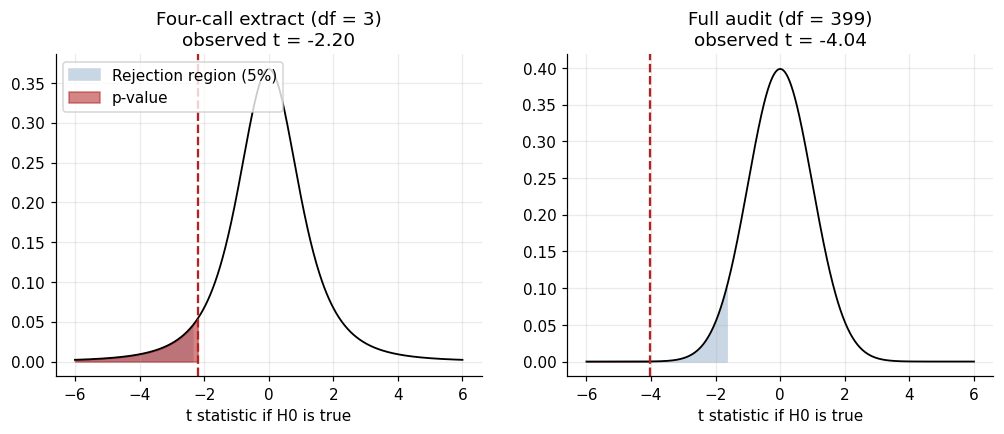

In [24]:
# 3. Where the observed statistic falls: four calls versus 400 calls
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, df_, t_obs, title in [(axes[0], 3, t_hand, "Four-call extract (df = 3)"),
                              (axes[1], n - 1, t_full, f"Full audit (df = {n - 1})")]:
    xs = np.linspace(-6, 6, 800)
    ys = stats.t.pdf(xs, df_)
    crit = stats.t.ppf(0.05, df_)
    ax.plot(xs, ys, color="black", lw=1.2)
    ax.fill_between(xs, ys, where=xs <= crit, color="#c9d6e3", label="Rejection region (5%)")
    ax.fill_between(xs, ys, where=xs <= t_obs, color="firebrick", alpha=0.55, label="p-value")
    ax.axvline(t_obs, color="firebrick", ls="--")
    ax.set_title(f"{title}\nobserved t = {t_obs:.2f}")
    ax.set_xlabel("t statistic if H0 is true")
axes[0].legend(loc="upper left"); plt.show()

In [12]:
# 4. z or t? Critical values converge as n grows, and the z interval under-covers when n is small
crit_table = pd.DataFrame({"n": [4, 10, 30, 100, 400]})
crit_table["t critical (one-sided 5%)"] = stats.t.ppf(0.95, crit_table["n"] - 1)
crit_table["z critical (one-sided 5%)"] = stats.norm.ppf(0.95)
crit_table["t multiplier (95% CI)"] = stats.t.ppf(0.975, crit_table["n"] - 1)
print(crit_table.round(3).to_string(index=False))

cov_rows = []
for n_i in (10, 25, 100):
    smp = population[rng.integers(0, population.size, size=(10_000, n_i))]
    smp_mean, smp_se = smp.mean(axis=1), smp.std(axis=1, ddof=1) / np.sqrt(n_i)
    for label, mult in [("z multiplier 1.96, s plugged in", 1.96),
                        ("t multiplier, df = n - 1", stats.t.ppf(0.975, n_i - 1))]:
        hit = ((smp_mean - mult * smp_se <= mu_true) & (mu_true <= smp_mean + mult * smp_se)).mean()
        cov_rows.append({"n": n_i, "interval": label, "coverage": hit})
cov_table = pd.DataFrame(cov_rows)
print("\nShare of 10,000 nominal 95% intervals that captured the true mean:")
print(cov_table.assign(coverage=cov_table["coverage"].map("{:.1%}".format)).to_string(index=False))

  n  t critical (one-sided 5%)  z critical (one-sided 5%)  t multiplier (95% CI)
  4                      2.353                      1.645                  3.182
 10                      1.833                      1.645                  2.262
 30                      1.699                      1.645                  2.045
100                      1.660                      1.645                  1.984
400                      1.649                      1.645                  1.966

Share of 10,000 nominal 95% intervals that captured the true mean:
  n                        interval coverage
 10 z multiplier 1.96, s plugged in    91.0%
 10        t multiplier, df = n - 1    94.4%
 25 z multiplier 1.96, s plugged in    93.3%
 25        t multiplier, df = n - 1    94.4%
100 z multiplier 1.96, s plugged in    94.4%
100        t multiplier, df = n - 1    94.6%


**Reading the result.**

- The SciPy test on the four calls matches the hand calculation: $t = -2.197$, $p = 0.0577$.
- On the 400-call audit, $t = -4.04$ with 399 degrees of freedom and $p = 0.00003$. If the tool truly did nothing, an audit this favourable would turn up in roughly 3 of every 100,000 audits.
- The z-test with known $\sigma$ gives $p = 0.00003$, practically the same answer at $n = 400$. The four tests in the table agree on the verdict: reject $H_0$.
- The picture shows why sample size matters. With four calls the observed statistic sits just outside the rejection region. With 400 calls it lands far inside it. The hypotheses and the rule are identical, and only the amount of evidence changed.
- The t critical value falls from 2.353 at $n=4$ to 1.649 at $n=400$, closing in on the z value of 1.645. At $n = 10$ the z-style interval captured the true mean only 91.0% of the time, against 94.4% for the t interval; by $n = 100$ both are close to 95%.

## Business Application

**Stakeholders: Paolo Reyes (decision) and the finance committee (approval).**

- **Result in plain language.** If the tool had no effect, an audit this favourable would occur in about 3 of every 100,000 audits. Paolo can say that the pilot team's AHT is genuinely below the benchmark and that the drop is not a lucky month.
- **What the test does not say.** It does not say how large the drop is, or whether it is large enough to repay ₱18.0 million. A p-value answers "is there an effect?" The interval from Subtopic 2 answers "how big?" Paolo needs both.
- **Decision hygiene.** The hypotheses, the one-sided alternative and $\alpha = 0.05$ are fixed before the committee sees the results. Changing any of them after seeing the data would make the p-value meaningless.

### Subtopic 4 · Type I and Type II Errors as a Business Trade-off

**Business Hook:** Finance asks *"If we are going to be wrong, which mistake can Isla better afford: paying ₱18.0 million for a tool that does not help, or walking away from one that would have saved us ₱18.0 million?"*

## Intuition & Analogy

A smoke alarm can fail in two ways. It can ring when there is no fire (a false alarm: annoying and cheap) or stay silent during a fire (a missed detection: catastrophic). Making it more sensitive trades fewer missed fires for more false alarms, and the right sensitivity depends on what each failure costs, not on a universal rule.

A hypothesis test fails in the same two ways:

- **Type I error (false positive):** rejecting $H_0$ when it is true. Isla signs the licence for a tool that does not reduce handle time. Its probability is $\alpha$.
- **Type II error (false negative):** failing to reject $H_0$ when it is false. Isla walks away from a tool that would have worked. Its probability is $\beta$, and **power** is $1-\beta$.

| | Tool truly works | Tool does not work |
|---|---|---|
| **Sign the licence** (reject $H_0$) | Correct: savings captured | Type I: ₱18.0 million paid for no benefit |
| **Pass** (fail to reject $H_0$) | Type II: ₱18.0 million of net savings forgone | Correct: wasted licence avoided |

At a fixed sample size, lowering $\alpha$ raises $\beta$. The only way to lower both is to collect more data.

## Theory — By Hand

**Costs.** A Type I error costs the full contract, ₱18.0 million. For a Type II error, define "the tool works" as a true reduction of 1.0 minute ($\mu_a = 10.0$). That reduction is worth ₱36.0 million over the contract, so passing forgoes $36.0 - 18.0 = ₱18.0$ million net.

**Worked example: the pilot Isla originally planned, $n = 100$, $\sigma = 4.0$ treated as known, one-sided $\alpha = 0.05$.**

1. Standard error: $4.0/\sqrt{100} = 0.40$.
2. Rejection threshold for the sample mean: $11.0 - 1.645(0.40) = 10.342$. Reject $H_0$ whenever $\bar{x}$ comes in below it.
3. If the true mean is 10.0, the chance of landing above the threshold, which is a Type II error, is
$$\beta = P\!\left(Z > \frac{10.342 - 10.0}{0.40}\right) = P(Z > 0.855) = 0.1962.$$
4. Power: $1 - \beta = 0.8038$.

**Moving the dial.** Tighten to $\alpha = 0.01$: threshold $= 11.0 - 2.326(0.40) = 10.069$ and $\beta = P(Z > 0.174) = 0.4311$. Cutting false positives from 5% to 1% more than doubles the false-negative rate. Loosen to $\alpha = 0.10$: threshold $= 11.0 - 1.282(0.40) = 10.487$ and $\beta = 0.1115$.

**Expected cost of a decision rule**, assuming the tool is equally likely to work or not:

$$E[\text{cost}] = 0.5\,\alpha\,C_I + 0.5\,\beta\,C_{II}, \qquad C_I = C_{II} = ₱18.0\text{ million}$$

| $\alpha$ | $\beta$ | Expected cost |
|---|---|---|
| 0.01 | 0.4311 | 3.97 million |
| 0.05 | 0.1962 | 2.22 million |
| 0.10 | 0.1115 | 1.90 million |

Of these three rules the cheapest is $\alpha = 0.10$, not the conventional 0.05.

## By Tool

The code wraps the by-hand power calculation in a function and checks it, confirms it by simulating 10,000 pilots on skewed call data, draws the two error areas, and then searches for the cost-minimising $\alpha$ under different cost ratios.

In [13]:
# 1. A reusable power calculation, checked against the by-hand example
def z_test_power(n, sigma, mu0, mu_a, alpha):
    # One-sided (lower-tail) z-test of H0: mu = mu0 against H1: mu < mu0
    se_ = sigma / np.sqrt(n)
    threshold = mu0 - stats.norm.ppf(1 - alpha) * se_       # reject H0 if the sample mean falls below this
    beta_ = 1 - stats.norm.cdf((threshold - mu_a) / se_)    # P(sample mean above threshold | true mean = mu_a)
    return threshold, beta_, 1 - beta_

thr_05, beta_05, pow_05 = z_test_power(100, SIGMA0, MU0, 10.0, 0.05)
thr_01, beta_01, pow_01 = z_test_power(100, SIGMA0, MU0, 10.0, 0.01)
print(f"alpha = 0.05: threshold = {thr_05:.3f}, beta = {beta_05:.4f}, power = {pow_05:.4f}")
print(f"alpha = 0.01: threshold = {thr_01:.3f}, beta = {beta_01:.4f}, power = {pow_01:.4f}")

alpha = 0.05: threshold = 10.342, beta = 0.1962, power = 0.8038
alpha = 0.01: threshold = 10.069, beta = 0.4311, power = 0.5689


In [14]:
# 2. Simulation check: 10,000 pilots of 100 calls each, using skewed (gamma) call times and a t-test
def rejection_rate(true_mean, n_calls=100, reps=10_000, alpha=0.05):
    shape, scale = (true_mean / SIGMA0) ** 2, SIGMA0 ** 2 / true_mean
    data = rng.gamma(shape, scale, size=(reps, n_calls))
    t_stat = (data.mean(axis=1) - MU0) / (data.std(axis=1, ddof=1) / np.sqrt(n_calls))
    return (t_stat < stats.t.ppf(alpha, df=n_calls - 1)).mean()

type1_rate = rejection_rate(11.0)      # the tool does nothing, so every rejection is a false positive
power_sim = rejection_rate(10.0)       # the tool cuts AHT by 1.0 minute, so every rejection is correct
print(f"Type I error rate when the true mean is 11.0: {type1_rate:.3f}  (target 0.050)")
print(f"Power when the true mean is 10.0:             {power_sim:.3f}  (z formula: {pow_05:.3f})")

Type I error rate when the true mean is 11.0: 0.060  (target 0.050)
Power when the true mean is 10.0:             0.786  (z formula: 0.804)


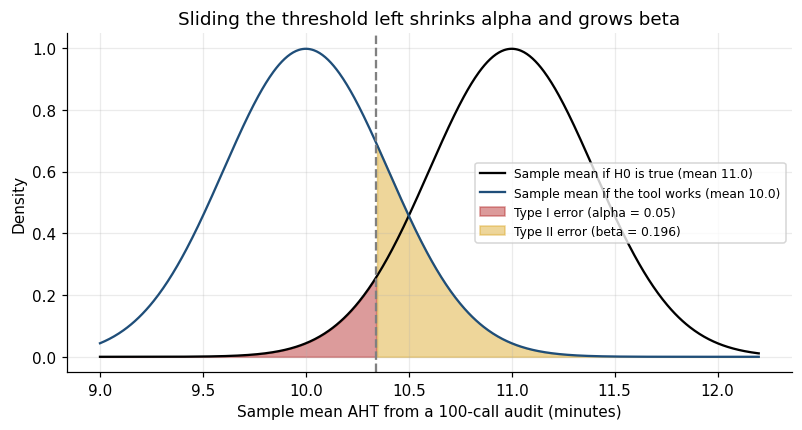

In [15]:
# 3. The two error areas at n = 100
se100 = SIGMA0 / np.sqrt(100)
xs = np.linspace(9.0, 12.2, 700)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(xs, stats.norm.pdf(xs, MU0, se100), color="black", label="Sample mean if H0 is true (mean 11.0)")
ax.plot(xs, stats.norm.pdf(xs, 10.0, se100), color="#1f4e79", label="Sample mean if the tool works (mean 10.0)")
ax.fill_between(xs, stats.norm.pdf(xs, MU0, se100), where=xs <= thr_05, color="firebrick", alpha=0.45,
                label="Type I error (alpha = 0.05)")
ax.fill_between(xs, stats.norm.pdf(xs, 10.0, se100), where=xs >= thr_05, color="goldenrod", alpha=0.45,
                label=f"Type II error (beta = {beta_05:.3f})")
ax.axvline(thr_05, color="gray", ls="--")
ax.set_xlabel("Sample mean AHT from a 100-call audit (minutes)"); ax.set_ylabel("Density")
ax.set_title("Sliding the threshold left shrinks alpha and grows beta"); ax.legend(fontsize=8); plt.show()

In [16]:
# 4. The trade-off in pesos: error rates and expected cost for two audit sizes
C_I = total_cost                              # Type I: licence signed for no benefit
C_II = value_per_minute * 1.0 - total_cost    # Type II: net savings forgone if the true reduction is 1.0 minute
p_works = 0.5                                 # equal prior chance that the tool works or does not

def expected_cost(alpha_, n_calls, c2=C_II):
    _, beta_, _ = z_test_power(n_calls, SIGMA0, MU0, 10.0, alpha_)
    return (1 - p_works) * alpha_ * C_I + p_works * beta_ * c2

rows = []
for n_calls in (100, 400):
    for a in (0.01, 0.025, 0.05, 0.10, 0.20):
        _, b, pw = z_test_power(n_calls, SIGMA0, MU0, 10.0, a)
        rows.append({"n": n_calls, "alpha": a, "beta": b, "power": pw,
                     "expected cost (PHP million)": expected_cost(a, n_calls) / 1e6})
tradeoff = pd.DataFrame(rows)
print(tradeoff.round(4).to_string(index=False))

  n  alpha   beta  power  expected cost (PHP million)
100  0.010 0.4311 0.5689                       3.9696
100  0.025 0.2946 0.7054                       2.8763
100  0.050 0.1962 0.8038                       2.2161
100  0.100 0.1115 0.8885                       1.9037
100  0.200 0.0486 0.9514                       2.2376
400  0.010 0.0038 0.9962                       0.1238
400  0.025 0.0012 0.9988                       0.2356
400  0.050 0.0004 0.9996                       0.4536
400  0.100 0.0001 0.9999                       0.9009
400  0.200 0.0000 1.0000                       1.8001


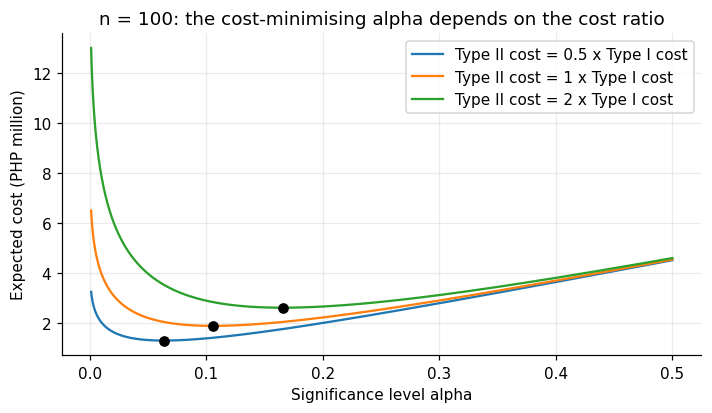

Type II cost = 0.5 x Type I cost -> cost-minimising alpha = 0.063
Type II cost = 1 x Type I cost -> cost-minimising alpha = 0.106
Type II cost = 2 x Type I cost -> cost-minimising alpha = 0.165

Calls needed for 80% power at alpha = 0.05 to detect a 1.0-minute reduction: 99
Calls needed for 80% power at alpha = 0.05 to detect a 0.5-minute reduction: 396
At n = 400 and alpha = 0.05: beta for a 1.0-minute reduction = 0.00040; power for the 0.5-minute break-even effect = 0.804


In [17]:
# 5. Cost-minimising alpha under different cost ratios, and the audit size needed for 80% power
grid = np.linspace(0.001, 0.50, 1999)
best_alpha = {}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for ratio in (0.5, 1, 2):
    costs = np.array([expected_cost(a, 100, c2=ratio * C_I) for a in grid]) / 1e6
    best_alpha[ratio] = grid[costs.argmin()]
    ax.plot(grid, costs, label=f"Type II cost = {ratio} x Type I cost")
    ax.plot(best_alpha[ratio], costs.min(), "ko")
ax.set_xlabel("Significance level alpha"); ax.set_ylabel("Expected cost (PHP million)")
ax.set_title("n = 100: the cost-minimising alpha depends on the cost ratio"); ax.legend(); plt.show()
for ratio, a_best in best_alpha.items():
    print(f"Type II cost = {ratio} x Type I cost -> cost-minimising alpha = {a_best:.3f}")

def n_for_power(delta, sigma, alpha_, power_=0.80):
    return int(np.ceil(((stats.norm.ppf(1 - alpha_) + stats.norm.ppf(power_)) * sigma / delta) ** 2))

print()
for delta in (1.0, 0.5):
    print(f"Calls needed for 80% power at alpha = 0.05 to detect a {delta:.1f}-minute reduction: {n_for_power(delta, SIGMA0, 0.05)}")
_, beta_400, _ = z_test_power(400, SIGMA0, MU0, 10.0, 0.05)
_, _, power_400_be = z_test_power(400, SIGMA0, MU0, MU0 - breakeven, 0.05)
print(f"At n = 400 and alpha = 0.05: beta for a 1.0-minute reduction = {beta_400:.5f}; "
      f"power for the 0.5-minute break-even effect = {power_400_be:.3f}")

**Reading the result.**

- The function reproduces the hand calculation: threshold 10.342, $\beta$ 0.1962, power 0.8038.
- Simulating 10,000 pilots of skewed call data, the t-test rejects 0.060 of the time when the tool does nothing (target 0.050) and 0.786 of the time when the true mean is 10.0 (the formula gives 0.8038). The normal-theory calculation is a good guide, but with only 100 right-skewed calls the false-positive rate runs a little above 5% and power a little below the formula. The gap closes as $n$ grows.
- In the picture, the red area is the false-positive risk and the gold area is the false-negative risk. Sliding the threshold left shrinks one and grows the other.
- At $n = 100$ with equal costs the cost-minimising $\alpha$ is about 0.106. If a Type II error cost twice as much as a Type I error, the best $\alpha$ rises to about 0.165; if a Type I error cost twice as much, it falls to about 0.063.
- At $n = 400$, the audit Isla actually ran, both errors collapse for the 1.0-minute effect ($\beta$ is 0.00040 at $\alpha = 0.05$), and power against the 0.5-minute break-even effect is 0.804.

## Business Application

**Stakeholders: Paolo Reyes and Isla's Finance Controller.**

- **Make $\alpha$ a business choice.** With comparable costs on both sides and a small audit, the cost-minimising rule is looser than 5%. A cancellable licence would loosen it further, and an expensive locked-in contract would tighten it. The test cannot choose $\alpha$; the people who bear the costs must.
- **Size the audit to the decision.** About 396 audited calls gives 80% power to detect a 0.5-minute reduction, the smallest effect that matters financially. A smaller audit risks a Type II error on exactly the effect Isla cares about, and the 400 calls QA actually drew sit right at that threshold.
- **Put numbers on both errors early.** Before the next pilot, Paolo can ask Finance to write down the cost of each mistake, so that $\alpha$ and the sample size are set from those figures and not from habit.

### Subtopic 5 · Synthesis: One Mathematics, Two Views

**Business Hook:** Finance asks *"Do I need the p-value or the interval? Are these two separate analyses?"*

## Intuition & Analogy

Picture the confidence interval as a guest list: every benchmark value the data cannot rule out at the chosen level. A hypothesis test is a bouncer holding a single name, $\mu_0$, and checking whether it is on the list. If $\mu_0$ is inside the interval, the bouncer waves it through (fail to reject). If it is outside, it is turned away (reject). The list, the data and the standard error are the same in both cases. The test checks one name; the interval shows the whole list.

That makes the interval the richer answer. It delivers the verdict on every benchmark at once, and it shows how large the effect could be, which a p-value cannot.

## Theory — By Hand

A two-sided test at level $\alpha$ rejects $H_0: \mu = \mu_0$ exactly when

$$\left|\frac{\bar{x}-\mu_0}{SE}\right| > t^{*} \iff \mu_0 < \bar{x} - t^{*}\,SE \quad\text{or}\quad \mu_0 > \bar{x} + t^{*}\,SE,$$

that is, exactly when $\mu_0$ lies outside the $(1-\alpha)$ confidence interval. The centre $\bar{x}$, the standard error and the multiplier $t^{*}$ are shared, so nothing new has to be computed. A *one-sided* test at level $\alpha$ corresponds to a *two-sided* interval at level $1-2\alpha$, for example a 90% interval for a one-sided 5% test.

**Worked example: the same four calls.**

- **95% interval and two-sided test.** The interval $(4.82,\ 12.13)$ contains 11.0, so the two-sided test at 5% fails to reject. Check: $t = -2.197$ gives a two-sided p-value of $2 \times 0.0577 = 0.115$, which exceeds 0.05.
- **90% interval and one-sided test.** For 3 degrees of freedom, $t^{*}_{0.95} = 2.353$, so the interval is $8.475 \pm 2.353(1.1492) = (5.77,\ 11.18)$. Its upper bound, 11.18, is above 11.0, so the one-sided test fails to reject, matching the one-sided p-value of 0.0577, which exceeds 0.05.
- **What only the interval shows.** It also contains 10.5, so a break-even result is entirely consistent with these four calls. The test never asked about 10.5.

## By Tool

The code confirms the equivalence on the four calls, then at full scale across hundreds of benchmark values, then translates the interval into pesos and sizes a follow-up audit.

In [18]:
# 1. Duality on the four-call extract
ci95_3 = stats.t.interval(0.95, df=3, loc=x_bar, scale=se)
ci90_3 = stats.t.interval(0.90, df=3, loc=x_bar, scale=se)
p_two_3 = 2 * stats.t.sf(abs(t_hand), df=3)
print(f"95% CI: ({ci95_3[0]:.3f}, {ci95_3[1]:.3f}); contains {MU0}? {ci95_3[0] <= MU0 <= ci95_3[1]}")
print(f"Two-sided p-value for H0: mu = {MU0}: {p_two_3:.4f}; reject at 5%? {p_two_3 <= 0.05}")
print(f"90% CI: ({ci90_3[0]:.3f}, {ci90_3[1]:.3f}); upper bound below {MU0}? {ci90_3[1] < MU0}")
print(f"One-sided p-value: {p_hand:.4f}; reject at 5%? {p_hand <= 0.05}")

95% CI: (4.818, 12.132); contains 11.0? True
Two-sided p-value for H0: mu = 11.0: 0.1155; reject at 5%? False
90% CI: (5.771, 11.179); upper bound below 11.0? False
One-sided p-value: 0.0577; reject at 5%? False


Test and interval agree at all 521 benchmark values: True


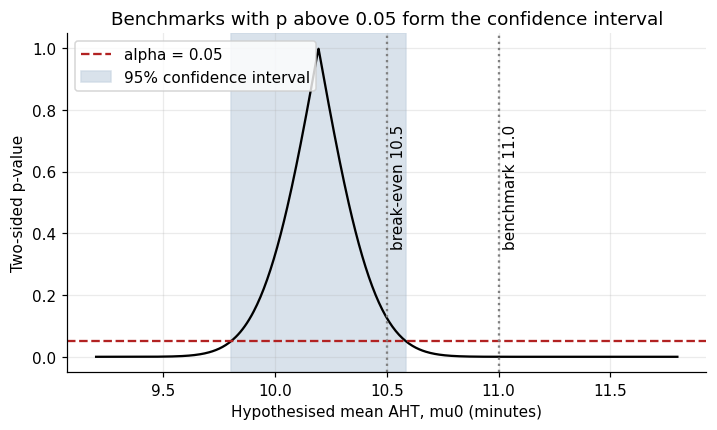

In [19]:
# 2. Full-scale duality: the 95% interval is the set of benchmarks that a two-sided 5% test cannot reject
mu_grid = np.linspace(9.2, 11.8, 521)
p_two = 2 * stats.t.sf(np.abs((x_bar_full - mu_grid) / se_full), df=n - 1)
in_ci = (mu_grid >= ci_lo) & (mu_grid <= ci_hi)
print(f"Test and interval agree at all {mu_grid.size} benchmark values: {np.array_equal(p_two > 0.05, in_ci)}")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(mu_grid, p_two, color="black")
ax.axhline(0.05, color="firebrick", ls="--", label="alpha = 0.05")
ax.axvspan(ci_lo, ci_hi, color="#c9d6e3", alpha=0.7, label="95% confidence interval")
ax.axvline(MU0, color="gray", ls=":")
ax.text(MU0 + 0.02, 0.55, "benchmark 11.0", rotation=90, va="center")
ax.axvline(MU0 - breakeven, color="gray", ls=":")
ax.text(MU0 - breakeven + 0.02, 0.55, "break-even 10.5", rotation=90, va="center")
ax.set_xlabel("Hypothesised mean AHT, mu0 (minutes)"); ax.set_ylabel("Two-sided p-value")
ax.set_title("Benchmarks with p above 0.05 form the confidence interval")
ax.legend(loc="upper left"); plt.show()

In [20]:
# 3. Selected benchmark values, and the one-sided / 90% interval pairing at full scale
rows = []
for mu0_i in (9.5, 10.0, 10.5, 11.0, 11.5):
    t_i = (x_bar_full - mu0_i) / se_full
    p_i = 2 * stats.t.sf(abs(t_i), df=n - 1)
    rows.append({"benchmark mu0": mu0_i, "t": t_i, "two-sided p": p_i,
                 "inside 95% CI": ci_lo <= mu0_i <= ci_hi, "reject at 5%": p_i <= 0.05})
print(pd.DataFrame(rows).round(4).to_string(index=False))

ci90 = stats.t.interval(0.90, df=n - 1, loc=x_bar_full, scale=se_full)
print(f"\n90% CI: ({ci90[0]:.3f}, {ci90[1]:.3f}); upper bound below {MU0}: {ci90[1] < MU0}; "
      f"one-sided p = {p_t_full:.6f}")

 benchmark mu0       t  two-sided p  inside 95% CI  reject at 5%
           9.5  3.4838       0.0005          False          True
          10.0  0.9757       0.3298           True         False
          10.5 -1.5325       0.1262           True         False
          11.0 -4.0406       0.0001          False          True
          11.5 -6.5488       0.0000          False          True

90% CI: (9.866, 10.523); upper bound below 11.0: True; one-sided p = 0.000032


In [21]:
# 4. From interval to decision: what the data say about money, and how many more calls would settle the question
red = MU0 - np.array([ci_hi, x_bar_full, ci_lo])      # reduction implied by the upper end, the estimate, the lower end
net = value_per_minute * red - total_cost
summary = pd.DataFrame({"AHT (min)": [ci_hi, x_bar_full, ci_lo],
                        "reduction (min)": red,
                        "net value over contract (PHP million)": net / 1e6},
                       index=["upper end of CI", "point estimate", "lower end of CI"])
print(summary.round(2).to_string())

target_moe = 0.15
n_needed = int(np.ceil((stats.norm.ppf(0.975) * s_full / target_moe) ** 2))
print(f"\nAudited calls needed for a margin of error of {target_moe} minute: {n_needed:,}")
print(f"If the estimate held, the upper end of the interval would be {x_bar_full + target_moe:.2f} "
      f"versus a break-even AHT of {MU0 - breakeven:.1f}")

                 AHT (min)  reduction (min)  net value over contract (PHP million)
upper end of CI      10.59             0.41                                  -3.11
point estimate       10.19             0.81                                  11.00
lower end of CI       9.80             1.20                                  25.11

Audited calls needed for a margin of error of 0.15 minute: 2,714
If the estimate held, the upper end of the interval would be 10.34 versus a break-even AHT of 10.5


**Reading the result.**

- The test and the interval give identical decisions at every one of the 521 benchmark values tested between 9.2 and 11.8 minutes. Benchmarks inside (9.80, 10.59) have two-sided p-values above 0.05, and benchmarks outside have p-values at or below 0.05.
- The one-sided test and the 90% interval agree as well: the interval's upper bound, 10.52, is below 11.0, and the one-sided p-value is 0.00003.
- Together they say that the reduction is real, because 11.0 is far outside the interval, but that its size is uncertain, because the 10.5-minute break-even is inside it. The p-value alone would have said "significant" and stopped there.

## Business Application

**Stakeholder: Paolo Reyes, making the recommendation.**

- **Pilot verdict.** AHT is reliably below the benchmark (one-sided p about 0.00003). The best estimate of the reduction is 0.81 minutes, and the plausible range of 0.41 to 1.20 minutes straddles the 0.5-minute break-even. The honest summary is "real, but not yet proven profitable."
- **Options for the committee.** Paolo can propose one of three routes: sign now and accept some chance that the true reduction falls below break-even; extend the audit, since about 2,714 calls would shrink the margin of error to 0.15 minute and, if the estimate held, put the whole interval below break-even; or negotiate a licence with a performance clause tied to measured AHT.
- **What the finding supports.** At the low end of the interval the contract loses ₱3.1 million, and at the high end it gains ₱25.1 million. A performance clause or a short audit extension removes most of the downside for a modest cost, so either is easier to defend to the committee than an unconditional ₱18.0 million commitment.

## Key Takeaways

**Subtopic 1: Point estimation and the standard error**

- A good estimate is unbiased (random sampling), precise (small SE), and consistent (improves with $n$).
- $SE = s/\sqrt{n}$ governs everything downstream; quadruple $n$ to halve it.
- The sample mean targets $\mu$; the median of skewed data targets something else.

**Subtopic 2: Confidence intervals**

- Interval = estimate $\pm\ t^{*} \times SE$; width responds to confidence level, variability and $n$.
- 95% is the long-run capture rate of the method, not the probability that this interval contains $\mu$.
- The interval describes the mean, not the spread of individual calls.
- A wide interval is information: it says the data are thin.

**Subtopic 3: Hypothesis testing framework**

- Steps: $H_0$ and $H_1$, $\alpha$, test statistic, p-value, decision, all set up before seeing the data.
- p-value $= P(\text{data this extreme} \mid H_0)$, not $P(H_0 \text{ is true})$.
- Fail to reject means "not proven," never "no effect."
- Use t whenever $\sigma$ is estimated; z only for known $\sigma$ or large $n$ (they converge by $n \approx 100$).
- Significance says an effect exists, not that it is large or profitable.

**Subtopic 4: Type I and Type II errors**

- $\alpha = P(\text{false positive})$, $\beta = P(\text{false negative})$, power $= 1-\beta$.
- At fixed $n$, lowering $\alpha$ raises $\beta$; only more data lowers both.
- Choose $\alpha$ by comparing the costs of the two errors; 5% is a convention, not a law.
- Size the audit for the smallest effect that matters financially (here 0.5 minute, about 400 calls for 80% power).

**Subtopic 5: Synthesis**

- A two-sided test at $\alpha$ rejects $\mu_0$ exactly when $\mu_0$ lies outside the $(1-\alpha)$ interval: same estimate, same SE, same multiplier.
- A one-sided test at $\alpha$ matches a two-sided $(1-2\alpha)$ interval.
- Report the interval with the p-value: the test says whether, the interval says how much.

## References

Casella, G., & Berger, R. L. (2002). *Statistical Inference* (2nd ed.). Duxbury.

Cumming, G., & Finch, S. (2005). Inference by eye: Confidence intervals and how to read pictures of data. *American Psychologist, 60*(2), 170–180.

Greenland, S., Senn, S. J., Rothman, K. J., Carlin, J. B., Poole, C., Goodman, S. N., & Altman, D. G. (2016). Statistical tests, P values, confidence intervals, and power: A guide to misinterpretations. *European Journal of Epidemiology, 31*(4), 337–350.

Montgomery, D. C., & Runger, G. C. (2014). *Applied Statistics and Probability for Engineers* (6th ed.). Wiley.

Morey, R. D., Hoekstra, R., Rouder, J. N., Lee, M. D., & Wagenmakers, E.-J. (2016). The fallacy of placing confidence in confidence intervals. *Psychonomic Bulletin & Review, 23*(1), 103–123.

Neyman, J., & Pearson, E. S. (1933). On the problem of the most efficient tests of statistical hypotheses. *Philosophical Transactions of the Royal Society A, 231*, 289–337.

Student. (1908). The probable error of a mean. *Biometrika, 6*(1), 1–25.

Wasserman, L. (2004). *All of Statistics: A Concise Course in Statistical Inference*. Springer.

Wasserstein, R. L., & Lazar, N. A. (2016). The ASA statement on p-values: Context, process, and purpose. *The American Statistician, 70*(2), 129–133.